# Análisis exploratorio de datos — MiBici 2025

**Proyecto:** TC5061 — Machine Learning Operations  
**Equipo:** 28  
**Fuente:** [MiBici — Datos Abiertos](https://www.mibici.net/es/datos-abiertos/)  
**Periodo:** Enero–diciembre de 2025

## Objetivo

Explorar los patrones de movilidad del sistema MiBici durante 2025, mediante el análisis de la actividad por estación y hora, la distribución temporal de los viajes y la cobertura de los datos.

Este análisis proporciona evidencia para las tres preguntas del proyecto:

- **P1 — Predicción de demanda:** identificar patrones temporales de salidas por estación.
- **P2 — Riesgo de desbalance:** analizar las diferencias entre llegadas y salidas como indicadores de presión operativa.
- **P3 — Agrupamiento de estaciones:** identificar diferencias en los perfiles de utilización de las estaciones.

## Datos utilizados

Se utiliza el archivo `data/processed/station_hourly_2025_complete.parquet`, generado por el pipeline reproducible del proyecto.

El dataset contiene registros por estación y hora con las variables `station_id`, `hour`, `departures`, `arrivals`, `net_flow`, `total_activity` e `is_observed_hour`.

**Consideración metodológica:** las horas completadas con ceros representan ausencia de actividad registrada, pero no permiten confirmar que la estación estuviera operativa durante esos periodos.

## Reproducibilidad

El notebook utiliza los archivos procesados por el pipeline oficial del proyecto y no modifica los datos originales. Su ejecución requiere que previamente se haya generado el dataset mediante el entrypoint `ingest` de MLflow.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Localizar la raíz del repositorio desde cualquier subdirectorio.
project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "No se encontró la raíz del repositorio. "
        "Ejecuta el notebook desde una carpeta del proyecto."
    )

# Cargar el dataset horario generado por el pipeline.
data_path = (
    project_root
    / "data"
    / "processed"
    / "station_hourly_2025_complete.parquet"
)

if not data_path.is_file():
    raise FileNotFoundError(
        f"No existe el dataset: {data_path}. "
        "Ejecuta primero el pipeline de ingesta."
    )

df = pd.read_parquet(data_path)

print(f"Dataset: {data_path.name}")
print(f"Registros: {len(df):,}")
print(f"Estaciones: {df['station_id'].nunique():,}")
print(f"Periodo: {df['hour'].min()} — {df['hour'].max()}")

display(df.head())

Dataset: station_hourly_2025_complete.parquet
Registros: 3,212,541
Estaciones: 371
Periodo: 2025-01-01 00:00:00 — 2025-12-31 23:00:00


,station_id,hour,departures,arrivals,net_flow,total_activity,is_observed_hour
0,2,2025-01-01 06:00:00,0,2,2,2,True
1,2,2025-01-01 07:00:00,0,0,0,0,False
2,2,2025-01-01 08:00:00,1,0,-1,1,True
3,2,2025-01-01 09:00:00,1,0,-1,1,True
4,2,2025-01-01 10:00:00,1,1,0,2,True


In [8]:
# Evaluar la calidad y cobertura del dataset horario.
total_registros = len(df)
horas_observadas = int(df["is_observed_hour"].sum())
horas_completadas = total_registros - horas_observadas

resumen_calidad = pd.DataFrame(
    {
        "Indicador": [
            "Registros totales",
            "Estaciones únicas",
            "Horas observadas",
            "Horas completadas",
            "Porcentaje de horas completadas",
            "Registros con valores nulos",
            "Registros con actividad cero",
        ],
        "Valor": [
            total_registros,
            df["station_id"].nunique(),
            horas_observadas,
            horas_completadas,
            round(100 * horas_completadas / total_registros, 2),
            int(df.isna().any(axis=1).sum()),
            int((df["total_activity"] == 0).sum()),
        ],
    }
)

display(resumen_calidad)

,Indicador,Valor
0,Registros totales,3212541.00
1,Estaciones únicas,371.00
2,Horas observadas,1887813.00
3,Horas completadas,1324728.00
4,Porcentaje de horas completadas,41.24
5,Registros con valores nulos,0.00
6,Registros con actividad cero,1324728.00


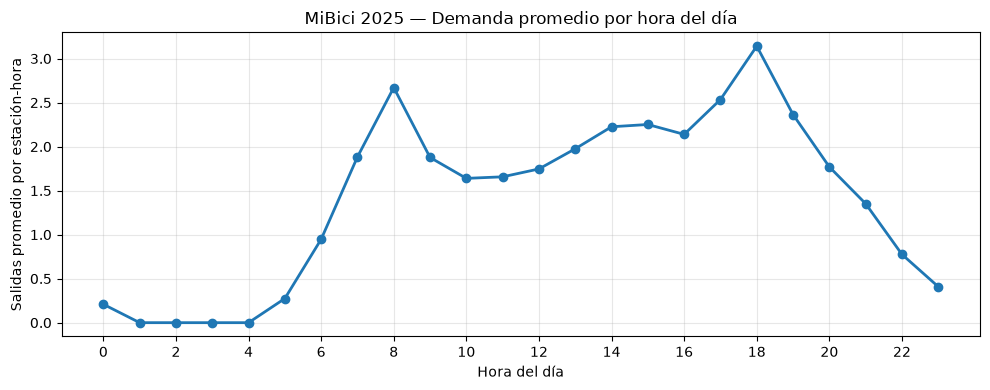

In [9]:
# Analizar las salidas promedio por estación según la hora del día.
actividad_horaria = (
    df.assign(hora_dia=df["hour"].dt.hour)
    .groupby("hora_dia")["departures"]
    .mean()
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    actividad_horaria.index,
    actividad_horaria.values,
    marker="o",
    linewidth=2,
)

ax.set(
    title="MiBici 2025 — Demanda promedio por hora del día",
    xlabel="Hora del día",
    ylabel="Salidas promedio por estación-hora",
)

ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

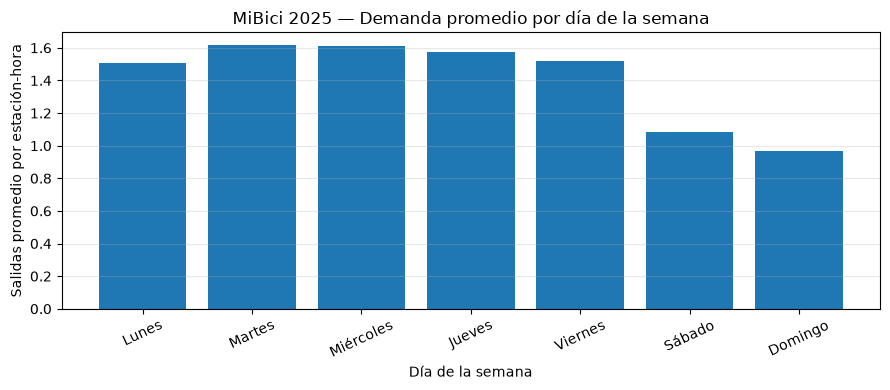

Mayor demanda: Martes (1.61 salidas por estación-hora)


In [10]:
# Calcular las salidas promedio por estación-hora y día de la semana.
dias = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo",
]

demanda_semanal = (
    df.assign(dia_semana=df["hour"].dt.dayofweek)
    .groupby("dia_semana")["departures"]
    .mean()
    .reindex(range(7))
)

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(dias, demanda_semanal.values)

ax.set(
    title="MiBici 2025 — Demanda promedio por día de la semana",
    xlabel="Día de la semana",
    ylabel="Salidas promedio por estación-hora",
)

ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print(
    "Mayor demanda:",
    dias[int(demanda_semanal.idxmax())],
    f"({demanda_semanal.max():.2f} salidas por estación-hora)",
)

,salidas,llegadas,actividad_total,flujo_neto
station_id,,,,
51,86834,112839,199673,26005
35,78027,93839,171866,15812
11,68640,64391,133031,-4249
271,68450,63440,131890,-5010
52,63933,61329,125262,-2604
50,56754,58575,115329,1821
54,52232,54510,106742,2278
260,39095,51316,90411,12221
38,38053,39111,77164,1058


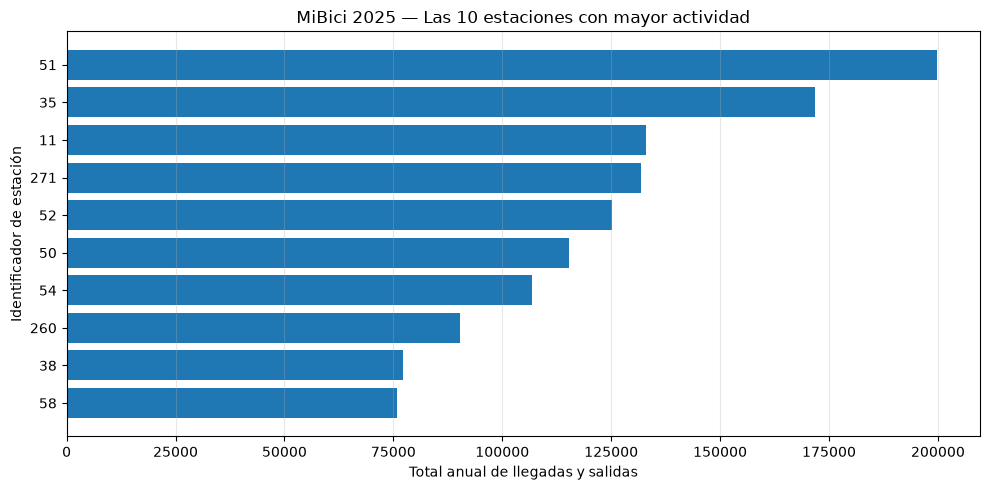

In [11]:
# Resumir la actividad anual por estación.
actividad_estaciones = (
    df.groupby("station_id")
    .agg(
        salidas=("departures", "sum"),
        llegadas=("arrivals", "sum"),
        actividad_total=("total_activity", "sum"),
        flujo_neto=("net_flow", "sum"),
    )
    .sort_values("actividad_total", ascending=False)
)

# Mostrar las diez estaciones con mayor actividad.
top_estaciones = actividad_estaciones.head(10)

display(top_estaciones)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    top_estaciones.index.astype(str)[::-1],
    top_estaciones["actividad_total"].values[::-1],
)

ax.set(
    title="MiBici 2025 — Las 10 estaciones con mayor actividad",
    xlabel="Total anual de llegadas y salidas",
    ylabel="Identificador de estación",
)

ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

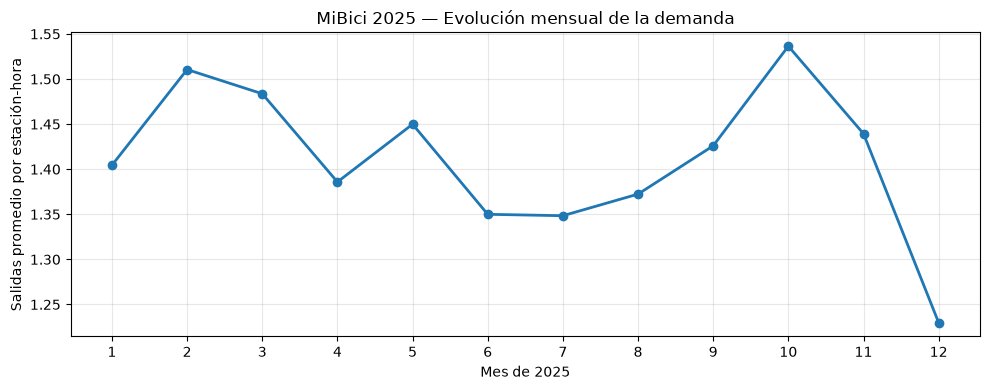

,salidas_promedio
mes,
1,1.404
2,1.511
3,1.484
4,1.386
5,1.450
6,1.350
7,1.348
8,1.372
9,1.426


In [12]:
# Analizar la evolución mensual de las salidas por estación-hora.
demanda_mensual = (
    df.assign(mes=df["hour"].dt.month)
    .groupby("mes")["departures"]
    .mean()
    .reindex(range(1, 13))
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    demanda_mensual.index,
    demanda_mensual.values,
    marker="o",
    linewidth=2,
)

ax.set(
    title="MiBici 2025 — Evolución mensual de la demanda",
    xlabel="Mes de 2025",
    ylabel="Salidas promedio por estación-hora",
)

ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(
    demanda_mensual.rename("salidas_promedio").round(3).to_frame()
)

## Conclusiones del análisis exploratorio

El análisis de los datos horarios de MiBici 2025 permitió identificar patrones temporales y diferencias operativas entre estaciones que respaldan las tres preguntas de machine learning del proyecto.

### Calidad y cobertura de datos

El dataset contiene **3,212,541 registros estación-hora correspondientes a 371 estaciones**, con cobertura temporal entre el 1 de enero y el 31 de diciembre de 2025. No se identificaron valores nulos.

El **41.24 % de los registros fueron incorporados mediante el completado de la serie temporal**, por lo que las horas con actividad cero deben interpretarse como ausencia de viajes registrados, no como evidencia de que las estaciones estuvieran fuera de servicio.

### Patrones temporales de demanda

La demanda presenta dos picos diarios, aproximadamente a las **08:00 y 18:00 horas**, y una mayor actividad durante los días laborales, especialmente martes y miércoles.

También se observaron variaciones mensuales. Octubre registró el promedio más alto, con **1.536 salidas por estación-hora**, mientras que diciembre presentó el menor, con **1.230**. Estas diferencias corresponden a 2025 y no permiten establecer por sí solas un patrón estacional recurrente.

### Diferencias entre estaciones

La actividad se concentra de manera desigual entre estaciones. La estación **51** registró 199,673 movimientos y la estación **35**, 171,866.

Asimismo, se identificaron diferencias entre llegadas y salidas. El flujo neto acumulado constituye un indicador descriptivo de estos movimientos, pero no representa directamente la disponibilidad real de bicicletas o espacios de anclaje.

### Implicaciones para el modelado

**P1 — Predicción de demanda:** los patrones horarios, semanales y mensuales respaldan el uso de variables temporales y justifican la evaluación sobre periodos futuros.

**P2 — Riesgo de desbalance:** las diferencias entre llegadas y salidas proporcionan información para construir indicadores indirectos de presión operativa. No deben interpretarse como eventos reales de estaciones llenas o vacías.

**P3 — Agrupamiento de estaciones:** las diferencias en volumen de actividad y flujo neto justifican explorar perfiles de estaciones mediante técnicas de clustering.

### Limitaciones

- Los registros completados con ceros no permiten confirmar la operación continua de las estaciones.
- El análisis agregado puede ocultar diferencias importantes entre estaciones individuales.
- El flujo neto de viajes no incorpora necesariamente movimientos de redistribución o mantenimiento.
- Las variaciones observadas corresponden a un solo año y no demuestran tendencias de largo plazo.

Este notebook documenta la exploración inicial de los datos y complementa el pipeline reproducible del proyecto, sin sustituir los experimentos formales registrados en MLflow.